# 04 · Model Evaluation
Load models trained by notebook 03 from persistent Google Drive artifacts. All scores are calculated from real held-out test predictions. If no model artifact exists, run notebook 03 first. Fraud class is positive label 1.


In [1]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib
from pathlib import Path
import pandas as pd, numpy as np, joblib, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import *
try:
 from google.colab import drive
 drive.mount('/content/drive')
except ImportError: pass
ROOT=Path('/content/drive/MyDrive/insurance_fraud_ml'); bundle_path=ROOT/'models/trained_models.joblib'
if not bundle_path.exists(): raise FileNotFoundError('Run notebook 03 first to train and save models')
bundle=joblib.load(bundle_path); models=bundle['models']; Xte=bundle['X_test']; yte=bundle['y_test']
rows=[]; preds={}; probs={}
for name,m in models.items():
 p=m.predict(Xte); q=m.predict_proba(Xte)[:,1]; preds[name]=p; probs[name]=q
 rows.append({'model':name,'accuracy':accuracy_score(yte,p),'precision':precision_score(yte,p,zero_division=0),'recall':recall_score(yte,p,zero_division=0),'f1':f1_score(yte,p,zero_division=0),'roc_auc':roc_auc_score(yte,q),'pr_auc':average_precision_score(yte,q)})
metrics=pd.DataFrame(rows).sort_values('pr_auc',ascending=False); display(metrics)
for name,p in preds.items(): print('\n'+name+'\n'+classification_report(yte,p,target_names=['Legitimate','Fraud'],zero_division=0))

Mounted at /content/drive


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
2,Random Forest,0.941310,0.700000,0.037838,0.071795,0.859200,0.297973
1,Decision Tree,0.865759,0.217284,0.475676,0.298305,0.691425,0.196401
0,Logistic Regression,0.643320,0.131939,0.886486,0.229692,0.806567,0.155922
3,K-Nearest Neighbors,0.934501,0.130435,0.016216,0.028846,0.655732,0.113809



Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.99      0.63      0.77      2899
       Fraud       0.13      0.89      0.23       185

    accuracy                           0.64      3084
   macro avg       0.56      0.76      0.50      3084
weighted avg       0.94      0.64      0.74      3084


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.96      0.89      0.93      2899
       Fraud       0.22      0.48      0.30       185

    accuracy                           0.87      3084
   macro avg       0.59      0.68      0.61      3084
weighted avg       0.92      0.87      0.89      3084


Random Forest
              precision    recall  f1-score   support

  Legitimate       0.94      1.00      0.97      2899
       Fraud       0.70      0.04      0.07       185

    accuracy                           0.94      3084
   macro avg       0.82      0.52      0.52      3084
weighted avg       0.93

## Confusion matrices and comparisons
False negatives are missed fraud; false positives are legitimate claims flagged for review. Precision-recall tradeoffs matter more than accuracy alone with imbalanced labels.

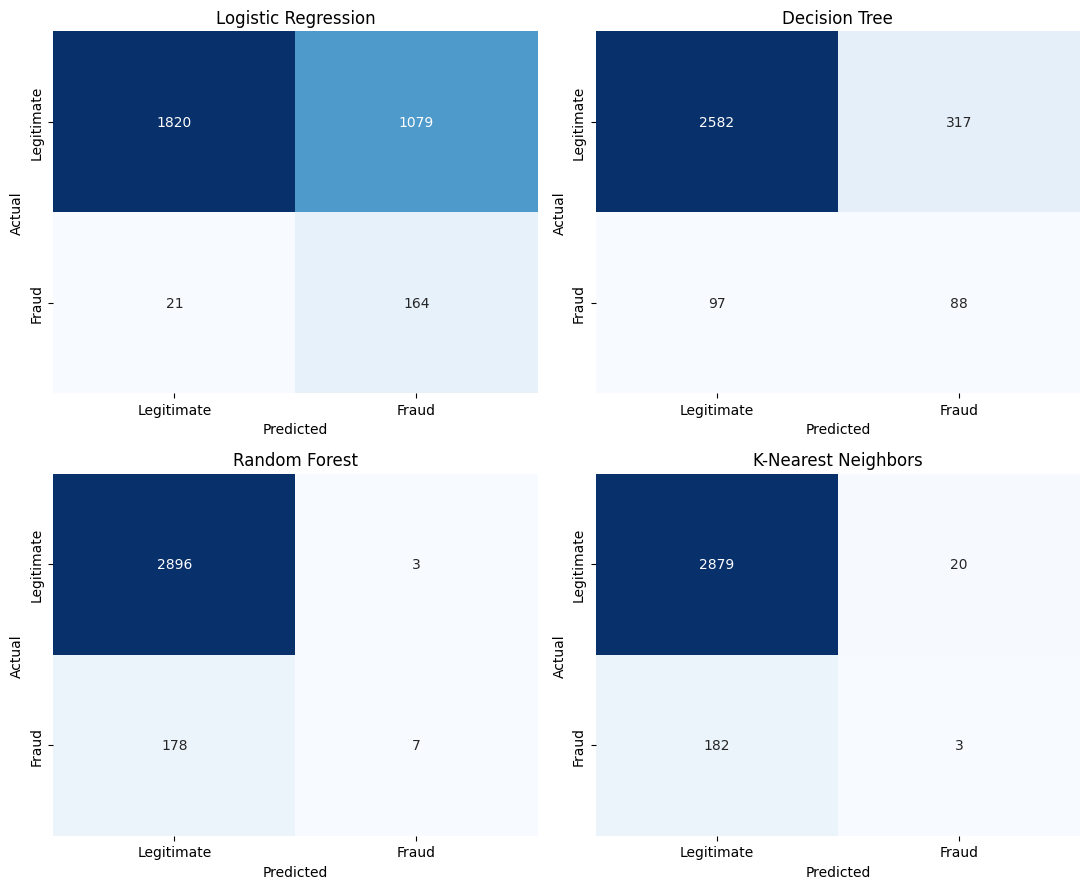

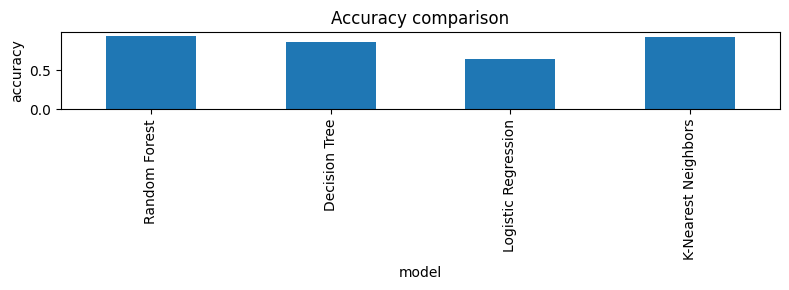

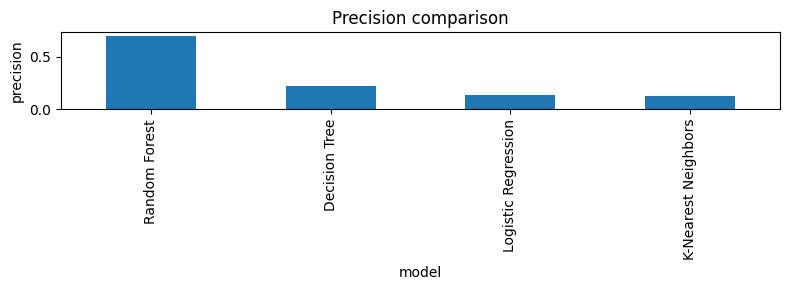

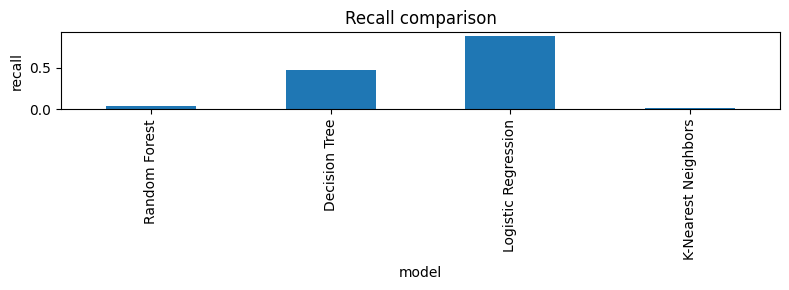

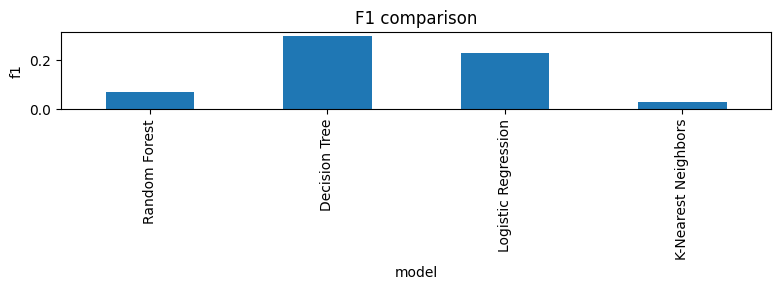

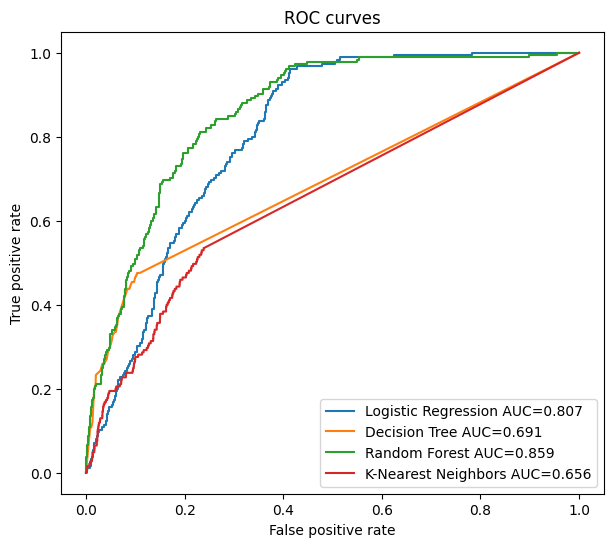

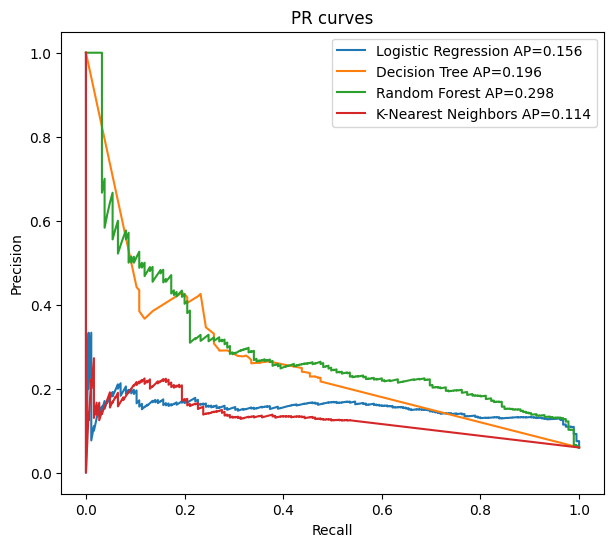

Select by highest actual PR-AUC: Random Forest
Default threshold retained at 0.50. Tune thresholds only on validation data, never on this test set.


In [2]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,(name,p) in zip(axes.ravel(),preds.items()): sns.heatmap(confusion_matrix(yte,p),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax,xticklabels=['Legitimate','Fraud'],yticklabels=['Legitimate','Fraud']); ax.set(title=name,xlabel='Predicted',ylabel='Actual')
plt.tight_layout(); plt.show()
for metric in ['accuracy','precision','recall','f1']:
 metrics.set_index('model')[metric].plot(kind='bar',title=metric.title()+' comparison',figsize=(8,3)); plt.ylabel(metric); plt.tight_layout(); plt.show()
for curve in ['roc','pr']:
 plt.figure(figsize=(7,6))
 for name,q in probs.items():
  if curve=='roc': a,b,_=roc_curve(yte,q); plt.plot(a,b,label=name+' AUC='+str(round(roc_auc_score(yte,q),3)))
  else: a,b,_=precision_recall_curve(yte,q); plt.plot(b,a,label=name+' AP='+str(round(average_precision_score(yte,q),3)))
 plt.xlabel('False positive rate' if curve=='roc' else 'Recall'); plt.ylabel('True positive rate' if curve=='roc' else 'Precision'); plt.title(curve.upper()+' curves'); plt.legend(); plt.show()
best=metrics.iloc[0]; print('Select by highest actual PR-AUC:',best['model']); print('Default threshold retained at 0.50. Tune thresholds only on validation data, never on this test set.')
metrics.to_csv(ROOT/'results/model_comparison.csv',index=False)

PR-AUC (average precision) is the baseline selection criterion because the fraud class is typically rare. Review precision, recall and the confusion matrix before making an operational choice. These are offline test metrics, not live production accuracy.